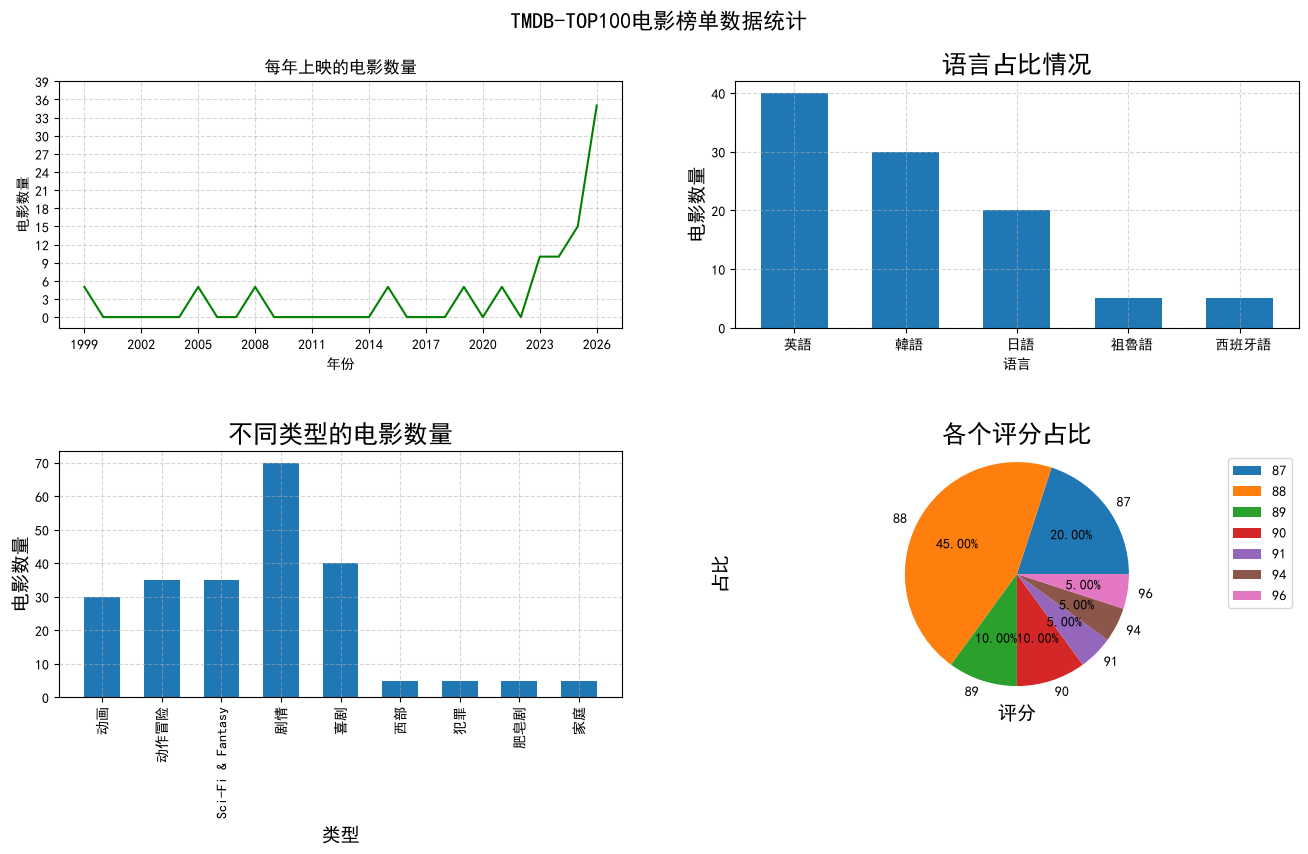

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei']

# 创建子图
fig, axes = plt.subplots(nrows = 2, ncols = 2, figsize = (16, 8), dpi = 100)

fig.suptitle("TMDB-TOP100电影榜单数据统计", fontsize = 16, x = 0.5, y = 0.97) # 添加总标题 x：水平位置 y：垂直位置

# 获取子图
axes1: plt.Axes = axes[0][0]
axes2: plt.Axes = axes[0][1]
axes3: plt.Axes = axes[1][0]
axes4: plt.Axes = axes[1][1]

# 加载数据
# Int64：支持空值
data = pd.read_csv("./data/movie_list.csv", usecols = ['电影名', '上映年份', '类型', '评分', '语言'], dtype = {'上映年份':'Int64'})



# 1、需求一：统计TOP100的电影中，每一年上映的电影数量的变化（折线图）
# 1.1、缺失值的处理
# 计算缺失值的数量
# data.isnull().sum()
# data['年份'] = data['年份'].fillna(data['上映年份'].str[:4]) #原教程中补充缺失值
# 1.2、分组统计
year_count = data.groupby('上映年份')['上映年份'].count()
# 1.3 组装数据
# x轴的数据
# year_count.index.min()
# year_count.index.max()
x = [i for i in range(year_count.index.min(), year_count.index.max() + 1)]
y = [int(year_count.get(i, 0)) for i in x]
axes1.plot(x, y, color = 'green')
axes1.set_title("每年上映的电影数量")
axes1.set_xlabel("年份")
axes1.set_ylabel("电影数量")
axes1.set_xticks(x[::3]);
y_ticks = [i for i in range(0,40,3)]
axes1.set_yticks(y_ticks);
axes1.grid(linestyle = '--', alpha = 0.5)


# 2、需求二：统计TOP100的电影中，语言的占比情况（柱状图）
# 后面加一个sort_values函数可以将这个表格排序一下
language_count = data.groupby('语言')['语言'].count().sort_values(ascending = False)
language_x = language_count.index.tolist()
language_y = language_count.values
axes2.bar(language_x, language_y, width = 0.6)
axes2.set_title("语言占比情况", fontsize = 18)
# 设置X轴标签
axes2.set_xlabel("语言", fontsize = 10)
# 设置y轴标签
axes2.set_ylabel("电影数量", fontsize = 14)
# 设置网格线
axes2.grid(linestyle= "--", alpha = 0.5)
# X轴的标签旋转一下代码，如果太挤了看不清可以使用
# axes2.tick_params(axis = 'x', rotation = 90)


# 3、需求三：统计对比不同类型的电影数量（柱状图）
# 3.1 获取不同类型的电影数量
type_count = {} # {'犯罪':3, '剧情':9}
for types in data['类型'].str.split('和'):
    for type in types:
        if type in type_count:
            type_count[type] += 1
        else:
            type_count[type] = 1
# print(type_count)
type_x = list(type_count.keys())
type_y = list(type_count.values())
axes3.bar(type_x, type_y, width = 0.6)
axes3.set_title("不同类型的电影数量", fontsize = 18)
axes3.set_xlabel("类型", fontsize = 14)
axes3.set_ylabel("电影数量", fontsize = 14)
axes3.grid(linestyle= "--", alpha = 0.5)
axes3.tick_params(axis = 'x', rotation = 90)


# 4、统计各个评分占比 (饼状图)
sources = data.groupby('评分')['电影名'].count()
# print(sources)
axes4.pie(sources.values, labels = sources.index, autopct = '%.2f%%')
axes4.set_title("各个评分占比", fontsize = 18)
axes4.set_xlabel("评分", fontsize = 14)
axes4.set_ylabel("占比", fontsize = 14)
axes4.axis('equal')
axes4.legend()

# 调整上下间距
fig.subplots_adjust(hspace=0.5)
plt.show()

